# ML Model for Factors Determining Severity 

In [1]:
# loading the required libraries
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, accuracy_score, recall_score, precision_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)

BLUE, ORANGE, GRAY, LIGHT = "#2a78d6", "#eb6834", "#52514e", "#b4b2a9"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#ecebe7", "axes.axisbelow": True, "axes.titleweight": "bold"})

In [2]:
# splitting into train and test sets
m = pd.read_csv("model_ready.csv")
X, y = m.drop(columns="High_Sev"), m["High_Sev"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(f"Train: {len(X_train):,}  Test: {len(X_test):,}  Features: {X.shape[1]}")
print(f"High severity share: train {y_train.mean():.3f}, test {y_test.mean():.3f}")

Train: 171,235  Test: 42,809  Features: 77
High severity share: train 0.340, test 0.340


In [3]:
# setting baseline
print(f"Baseline accuracy (always 'not severe'): {1 - y_test.mean():.3f}   Recall: 0.000")

Baseline accuracy (always 'not severe'): 0.660   Recall: 0.000


## Logistic Regression Model
Training model giving each feature weight and adds them to calculate the probability of severe

In [6]:
# Linear Regression Model
def evaluate(name, model, Xt, yt):
    p = model.predict_proba(Xt)[:, 1]
    pred = (p >= 0.5).astype(int)
    return {"Model": name, "ROC AUC": roc_auc_score(yt, p), "Accuracy": accuracy_score(yt, pred),
            "Recall (severe)": recall_score(yt, pred), "Precision (severe)": precision_score(yt, pred),
            "F1": f1_score(yt, pred)}

logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced"))
logreg.fit(X_train, y_train)
results = [evaluate("Logistic regression", logreg, X_test, y_test)]
pd.DataFrame(results).round(3)

,Model,ROC AUC,Accuracy,Recall (severe),Precision (severe),F1
0,Logistic regression,0.826,0.753,0.762,0.609,0.677


In [7]:
# Gradient Boosting Model
gb = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, class_weight="balanced", random_state=42)
gb.fit(X_train, y_train)
results.append(evaluate("Gradient boosting", gb, X_test, y_test))
results_df = pd.DataFrame(results).round(3)
results_df

,Model,ROC AUC,Accuracy,Recall (severe),Precision (severe),F1
0,Logistic regression,0.826,0.753,0.762,0.609,0.677
1,Gradient boosting,0.849,0.766,0.791,0.623,0.697


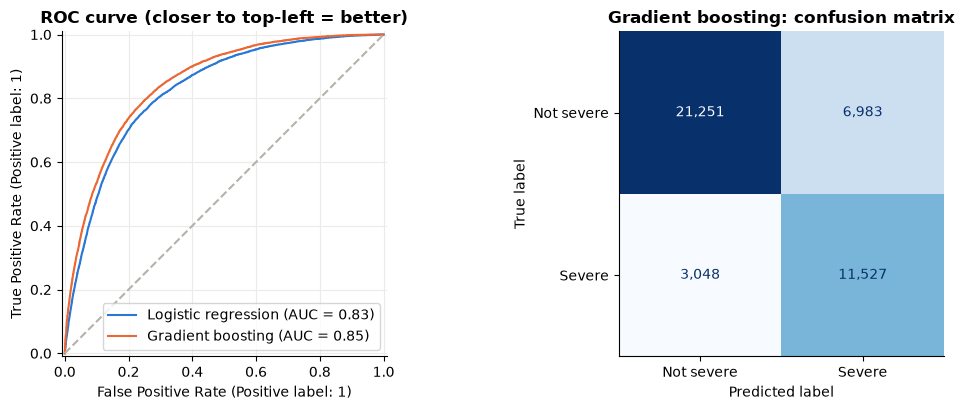

Caught 11,527 of 14,575 severe accidents (79%); 6,983 false alarms.


In [8]:
# Comparing the Two Models Visually
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
RocCurveDisplay.from_estimator(logreg, X_test, y_test, ax=axes[0], name="Logistic regression", curve_kwargs={"color": BLUE})
RocCurveDisplay.from_estimator(gb, X_test, y_test, ax=axes[0], name="Gradient boosting", curve_kwargs={"color": ORANGE})
axes[0].plot([0, 1], [0, 1], ls="--", color=LIGHT); axes[0].set_title("ROC curve (closer to top-left = better)")

cm = confusion_matrix(y_test, gb.predict(X_test))
ConfusionMatrixDisplay(cm, display_labels=["Not severe", "Severe"]).plot(ax=axes[1], cmap="Blues", colorbar=False, values_format=",")
axes[1].set_title("Gradient boosting: confusion matrix"); axes[1].grid(False)
plt.tight_layout(); plt.show()
tn, fp, fn, tp = cm.ravel()
print(f"Caught {tp:,} of {tp + fn:,} severe accidents ({tp/(tp+fn):.0%}); {fp:,} false alarms.")

In [9]:
# Regional Check
region = X_test[["Region_Midwest", "Region_Northeast", "Region_South", "Region_West"]].idxmax(axis=1).str.replace("Region_", "")
p = gb.predict_proba(X_test)[:, 1]; pred = (p >= 0.5).astype(int)
by_region = pd.DataFrame([{"Region": r, "Test accidents": int((region == r).sum()),
                           "ROC AUC": roc_auc_score(y_test[region == r], p[region == r]),
                           "Recall (severe)": recall_score(y_test[region == r], pred[region == r])}
                          for r in ["Midwest", "Northeast", "South", "West"]])
by_region.round(3)

,Region,Test accidents,ROC AUC,Recall (severe)
0,Midwest,5722,0.857,0.834
1,Northeast,5313,0.816,0.792
2,South,20777,0.864,0.783
3,West,10997,0.817,0.776


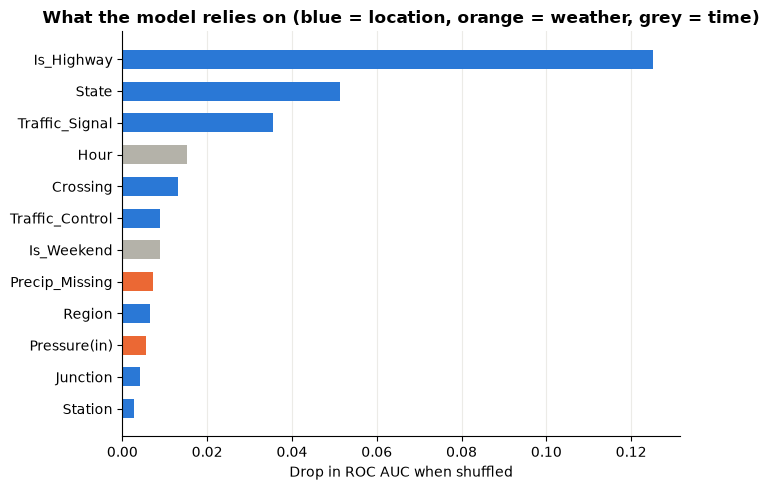

Is_Highway         0.1253
State              0.0514
Traffic_Signal     0.0354
Hour               0.0153
Crossing           0.0130
Traffic_Control    0.0090
Is_Weekend         0.0088
Precip_Missing     0.0072
Region             0.0066
Pressure(in)       0.0056
Junction           0.0041
Station            0.0027
dtype: float64

In [10]:
# Feature Importance to Severity
def group_of(col):
    for prefix, name in [("Region_", "Region"), ("State_Grp_", "State"), ("Weather_Group_", "Weather group"),
                         ("Time_of_Day_", "Time of day"), ("Wind_Direction_Clean_", "Wind direction")]:
        if col.startswith(prefix): return name
    return col
groups = {}
for c in X.columns: groups.setdefault(group_of(c), []).append(c)

rng = np.random.RandomState(0)
S = X_test.sample(10000, random_state=0); yS = y_test.loc[S.index]
base = roc_auc_score(yS, gb.predict_proba(S)[:, 1])
imp = {}
for g, cols in groups.items():
    drops = []
    for _ in range(3):
        Z = S.copy(); Z[cols] = Z[cols].values[rng.permutation(len(Z))]
        drops.append(base - roc_auc_score(yS, gb.predict_proba(Z)[:, 1]))
    imp[g] = np.mean(drops)
imp = pd.Series(imp).sort_values().tail(12)

kind = {"Is_Highway": "Location", "State": "Location", "Region": "Location", "Traffic_Signal": "Location",
        "Crossing": "Location", "Traffic_Control": "Location", "Junction": "Location", "Station": "Location",
        "Amenity": "Location", "Railway": "Location"}
colors = [BLUE if kind.get(k) == "Location" else (ORANGE if k in ["Weather group", "Bad_Weather", "Temperature(F)",
          "Humidity(%)", "Pressure(in)", "Visibility(mi)", "Wind_Speed(mph)", "Precipitation(in)", "Precip_Missing",
          "Wind direction"] else LIGHT) for k in imp.index]
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(imp.index, imp.values, color=colors, height=0.6)
ax.set_xlabel("Drop in ROC AUC when shuffled"); ax.grid(axis="y", visible=False)
ax.set_title("What the model relies on (blue = location, orange = weather, grey = time)")
plt.tight_layout(); plt.show()
imp.sort_values(ascending=False).round(4)

In [11]:
# Different Test Commuter Scenarios
gb_prob = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, random_state=42).fit(X_train, y_train)
print(f"Average predicted P(severe) on test: {gb_prob.predict_proba(X_test)[:, 1].mean():.3f} (actual: {y_test.mean():.3f})")

template = X_train.median(numeric_only=True).to_frame().T
for c in [c for c in X.columns if c.startswith(("Region_", "State_Grp_", "Weather_Group_", "Time_of_Day_", "Wind_Direction_Clean_"))]:
    template[c] = 0
template["State_Grp_Other"] = 1; template["Wind_Direction_Clean_Calm"] = 1

def scenario(region, highway, weather, time_of_day):
    row = template.copy()
    row[f"Region_{region}"] = 1
    row["Is_Highway"] = highway
    row[f"Weather_Group_{weather}"] = 1
    row["Bad_Weather"] = int(weather in ["Rain", "Snow/Ice", "Thunderstorm", "Fog/Low vis"])
    row[f"Time_of_Day_{time_of_day}"] = 1
    row["Is_Rush_Hour"] = int(time_of_day in ["Morning rush", "Evening rush"])
    row["Hour"] = {"Night": 2, "Morning rush": 8, "Midday": 12, "Evening rush": 17, "Evening": 21}[time_of_day]
    row["Is_Night"] = int(time_of_day in ["Night", "Evening"])
    return gb_prob.predict_proba(row[X.columns])[0, 1]

rows = []
for region in ["Midwest", "Northeast", "South", "West"]:
    for highway in [0, 1]:
        for weather in ["Clear/Fair", "Rain", "Snow/Ice", "Thunderstorm", "Fog/Low vis"]:
            for tod in ["Morning rush", "Evening rush", "Evening"]:
                rows.append({"Region": region, "Road": "Highway" if highway else "Local road",
                             "Weather": weather, "Time": tod,
                             "P(severe)": scenario(region, highway, weather, tod)})
scen = pd.DataFrame(rows)

# Evening rush: highway vs. local road, clear vs. bad weather (one row per region)
pivot = (scen[scen["Time"] == "Evening rush"].pivot_table(index="Region", columns=["Road", "Weather"], values="P(severe)") * 100).round(0)
pivot

Average predicted P(severe) on test: 0.338 (actual: 0.340)


Road         Highway                                         Local road  \
Weather   Clear/Fair Fog/Low vis  Rain Snow/Ice Thunderstorm Clear/Fair   
Region                                                                    
Midwest         84.0        87.0  87.0     89.0         87.0       55.0   
Northeast       61.0        67.0  67.0     70.0         66.0       35.0   
South           65.0        71.0  71.0     73.0         70.0       27.0   
West            61.0        67.0  67.0     70.0         66.0       34.0   

Road                                               
Weather   Fog/Low vis  Rain Snow/Ice Thunderstorm  
Region                                             
Midwest          62.0  62.0     65.0         63.0  
Northeast        42.0  42.0     45.0         43.0  
South            33.0  33.0     36.0         34.0  
West             41.0  41.0     44.0         42.0